In [14]:
import time
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
import missingno as msno

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

SEED = 0  # graine unique pour toute reproductibilite du notebook

orange = "#eb680e"
dark_blue = "#2a354a"
green = "#3f8f5f"
purple = "#7a5cc0"
rose = "#c94f6d"

cmap_light = ListedColormap(["#f7dcc7", "#c9d6e8"])
cmap_bold = ListedColormap([orange, dark_blue])

In [5]:
import kagglehub

# Download latest version
if os.path.exists("data"):
    path = kagglehub.dataset_download("parisrohan/credit-score-classification", output_dir="data")

print("Path to dataset files:", path)

100%|██████████| 9.51M/9.51M [00:01<00:00, 6.34MB/s]

Extracting files...


Path to dataset files: data


In [6]:
df = pd.read_csv("data/train.csv", low_memory=False)
print(df.shape)
df.head()

(100000, 28)


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,...,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,...,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good


In [9]:
df.columns

Index(['ID', 'Customer_ID', 'Month', 'Name', 'Age', 'SSN', 'Occupation',
       'Annual_Income', 'Monthly_Inhand_Salary', 'Num_Bank_Accounts',
       'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan',
       'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Credit_History_Age',
       'Payment_of_Min_Amount', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance',
       'Credit_Score'],
      dtype='str')

In [11]:
df.shape

(100000, 28)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  str    
 1   Customer_ID               100000 non-null  str    
 2   Month                     100000 non-null  str    
 3   Name                      90015 non-null   str    
 4   Age                       100000 non-null  str    
 5   SSN                       100000 non-null  str    
 6   Occupation                100000 non-null  str    
 7   Annual_Income             100000 non-null  str    
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12  Num_of_Loan               100000 non-null  str    
 13  Type_of_Loan              88592 non-null   str    
 14  

### variables a retypé
beacoup de varibles numériques sont saisi en format texte qu'il faudra formaté

In [30]:
print(f"Nombre de valeurs manquantes : {df.isna().sum().sum()}")
print(f"Proportion des valeurs manquantes : {df.isna().sum().sum()/len(df)*100}%")

Nombre de valeurs manquantes : 60071
Proportion des valeurs manquantes : 60.071%


In [35]:
df.isna().sum().sort_values(ascending=False)

Monthly_Inhand_Salary       15002
Type_of_Loan                11408
Name                         9985
Credit_History_Age           9030
Num_of_Delayed_Payment       7002
Amount_invested_monthly      4479
Num_Credit_Inquiries         1965
Monthly_Balance              1200
Month                           0
Age                             0
Customer_ID                     0
ID                              0
Interest_Rate                   0
Num_Credit_Card                 0
Num_Bank_Accounts               0
Annual_Income                   0
SSN                             0
Occupation                      0
Delay_from_due_date             0
Num_of_Loan                     0
Outstanding_Debt                0
Credit_Mix                      0
Changed_Credit_Limit            0
Credit_Utilization_Ratio        0
Total_EMI_per_month             0
Payment_of_Min_Amount           0
Payment_Behaviour               0
Credit_Score                    0
dtype: int64

<Axes: >

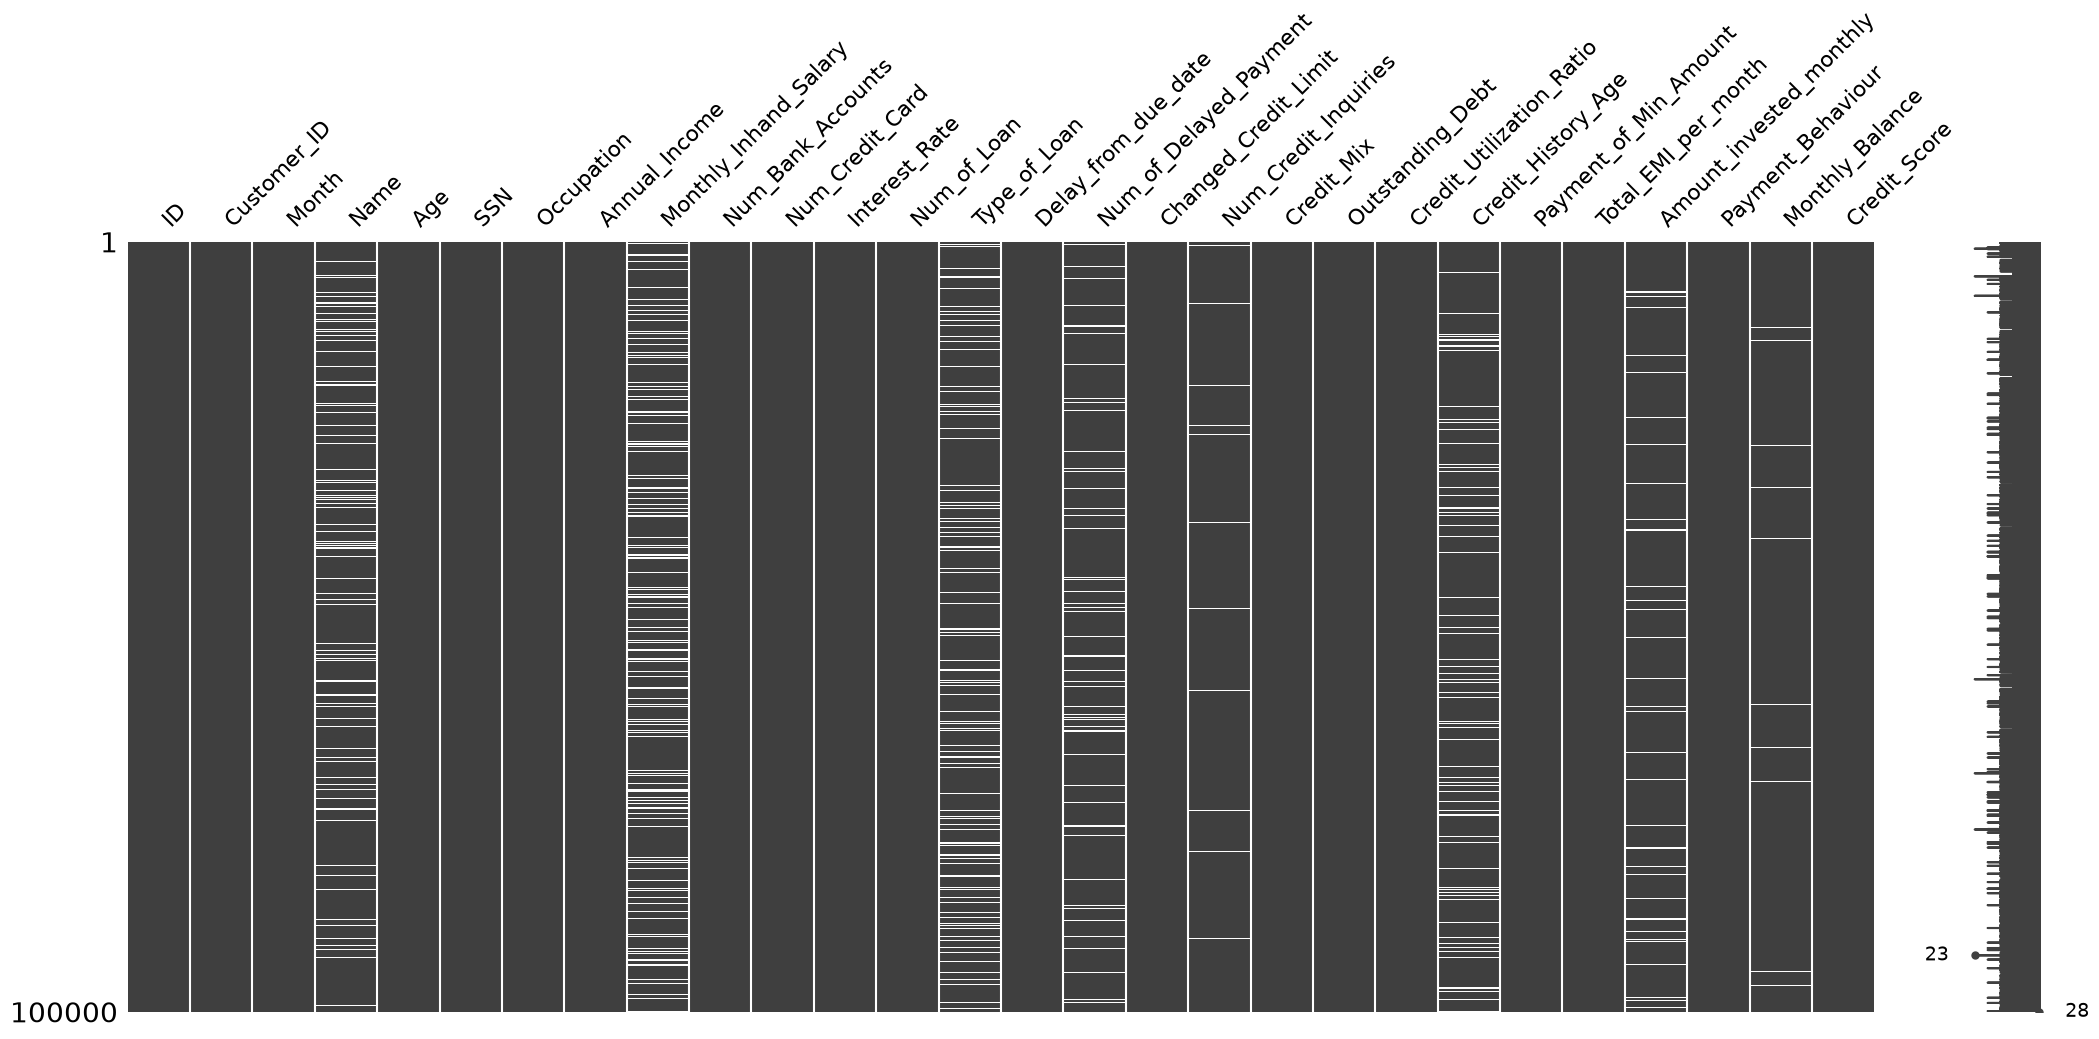

In [17]:
msno.matrix(df)

<Axes: >

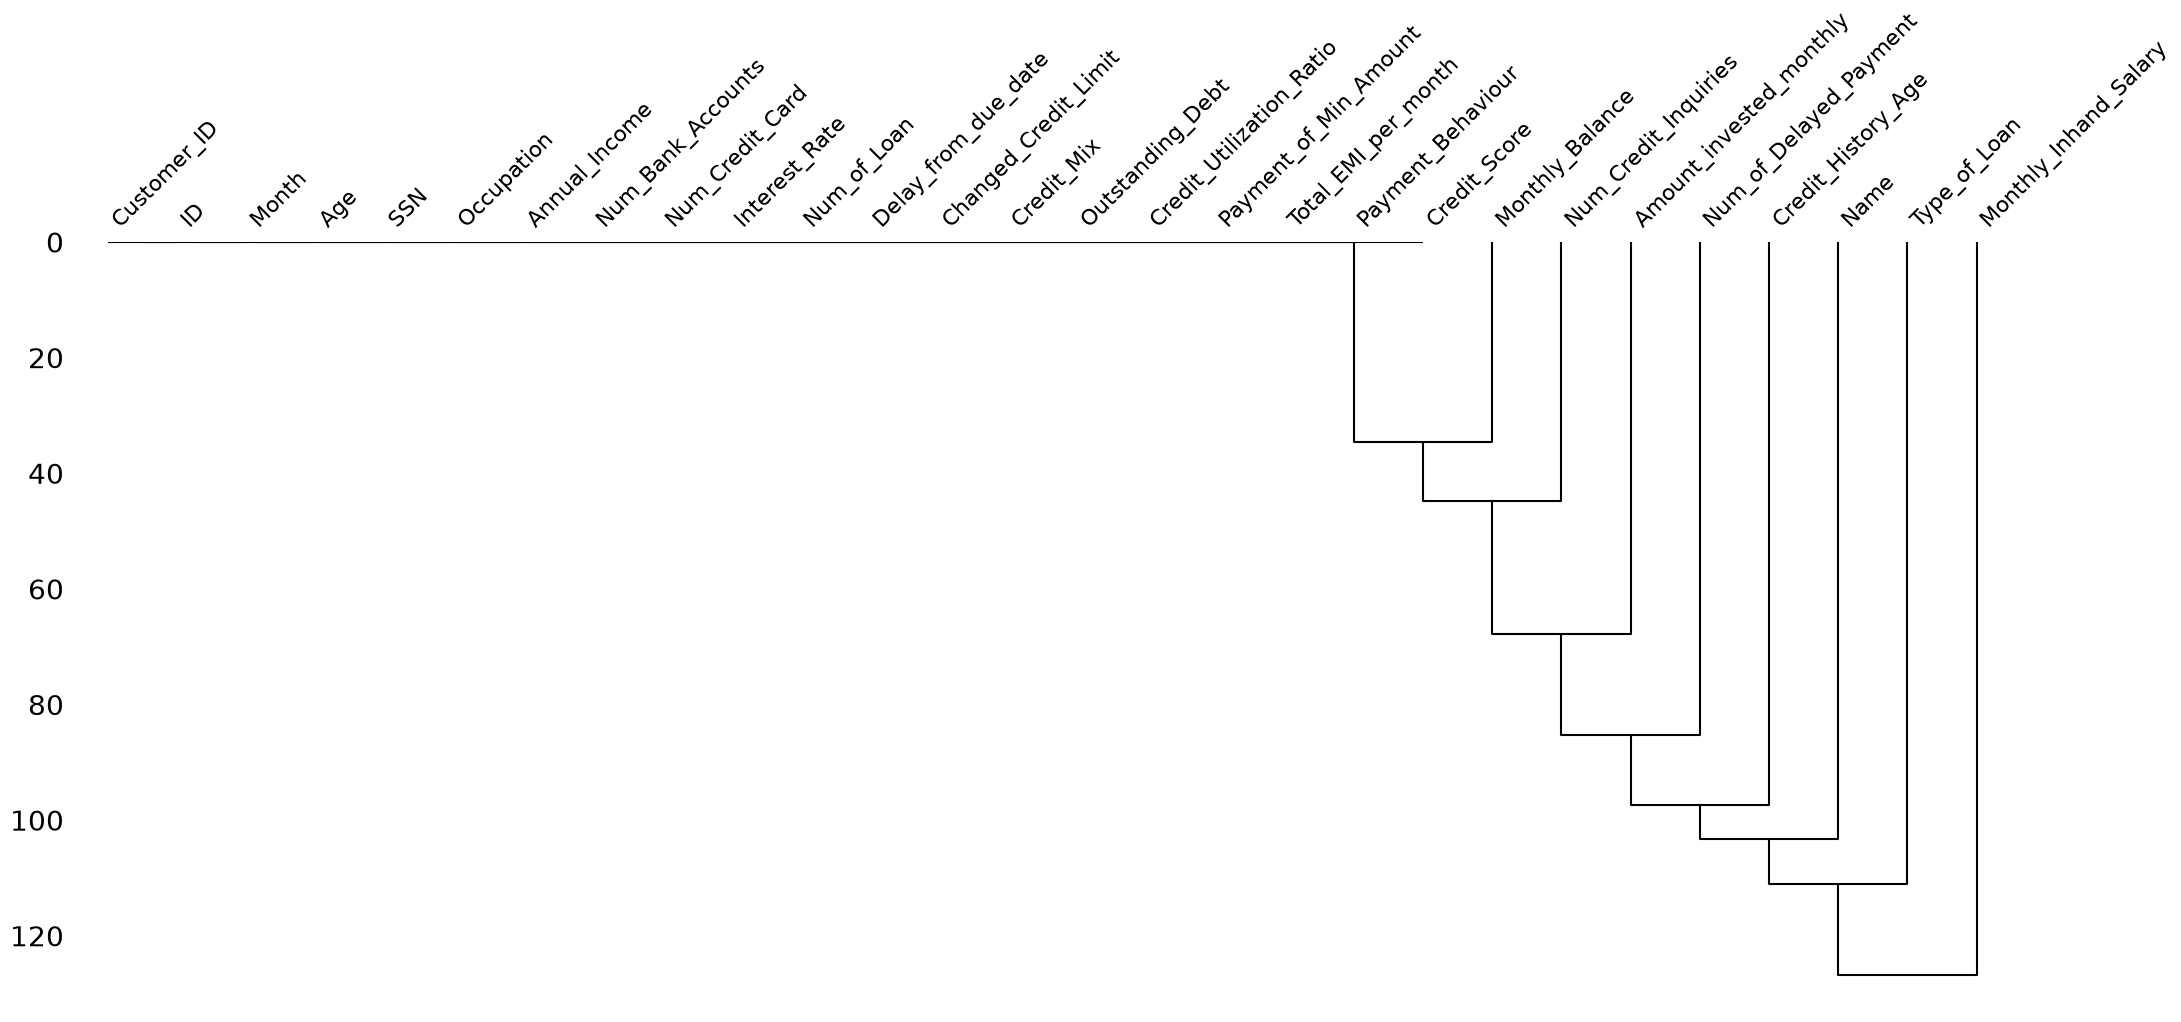

In [18]:
msno.dendrogram(df)

<Axes: >

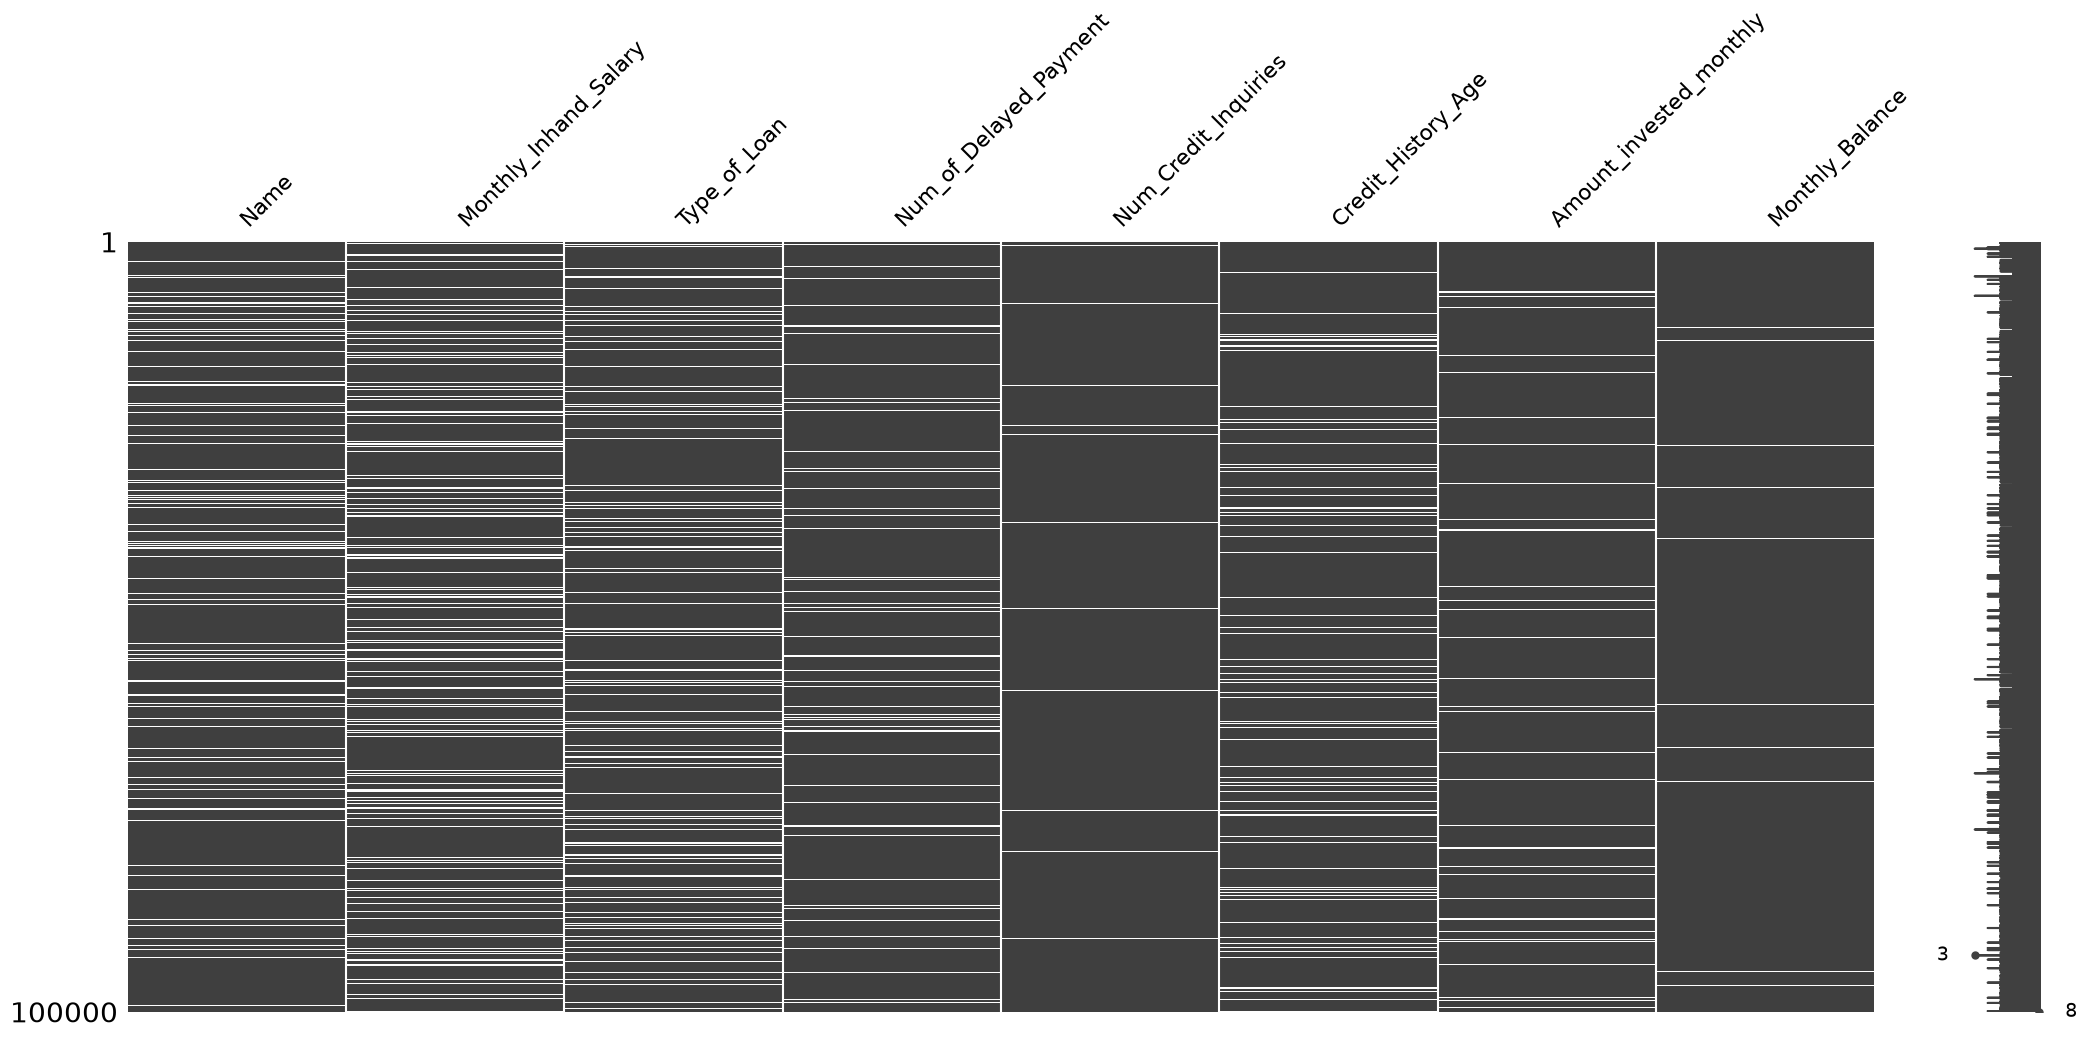

In [37]:
missing_cols = df.columns[df.isna().any()]
msno.matrix(df[missing_cols])

In [47]:
corr_missing = df[missing_cols].isna().corr().round(2)
corr_missing

,Name,Monthly_Inhand_Salary,Type_of_Loan,Num_of_Delayed_Payment,Num_Credit_Inquiries,Credit_History_Age,Amount_invested_monthly,Monthly_Balance
Name,1.00,-0.00,-0.00,-0.0,0.01,-0.00,-0.00,-0.00
Monthly_Inhand_Salary,-0.00,1.00,0.01,-0.0,-0.00,-0.00,0.01,-0.00
Type_of_Loan,-0.00,0.01,1.00,0.0,0.00,-0.00,-0.00,-0.03
Num_of_Delayed_Payment,-0.00,-0.00,0.00,1.0,-0.00,0.00,-0.00,0.00
Num_Credit_Inquiries,0.01,-0.00,0.00,-0.0,1.00,0.00,-0.00,0.00
Credit_History_Age,-0.00,-0.00,-0.00,0.0,0.00,1.00,-0.00,0.01
Amount_invested_monthly,-0.00,0.01,-0.00,-0.0,-0.00,-0.00,1.00,0.00
Monthly_Balance,-0.00,-0.00,-0.03,0.0,0.00,0.01,0.00,1.00


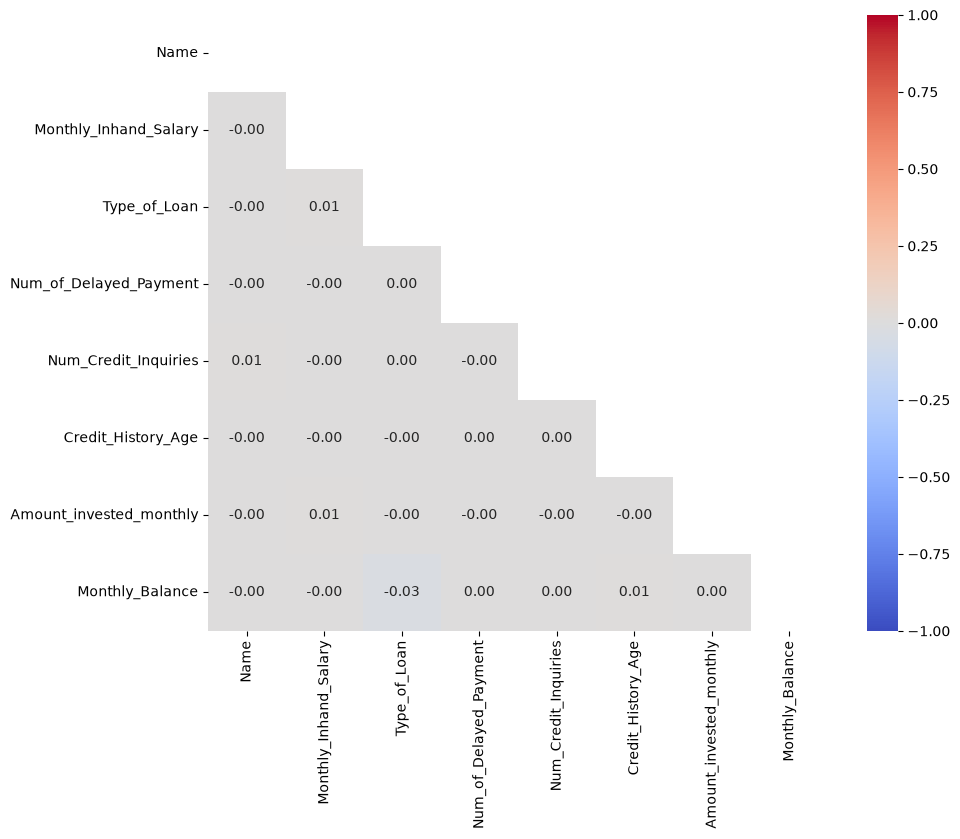

In [48]:

mask = np.triu(np.ones_like(corr_missing, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_missing,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.show()

## Variable cible

In [59]:
df["Credit_Score"].value_counts(normalize=True)*100


Credit_Score
Standard    53.174
Poor        28.998
Good        17.828
Name: proportion, dtype: float64

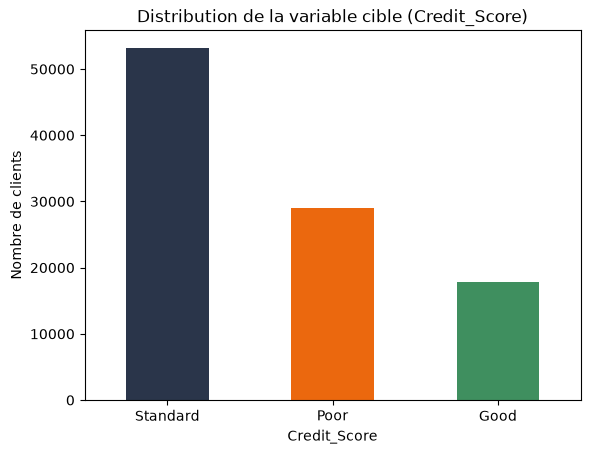

In [49]:

df["Credit_Score"].value_counts().plot(kind="bar", color=[dark_blue, orange, green])
plt.title("Distribution de la variable cible (Credit_Score)")
plt.ylabel("Nombre de clients")
plt.xticks(rotation=0)
plt.show()



### Variable cible déséquilibrée

In [ ]:
for 